In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator

from src.datos import cargar_datos
from src.dataset import MIN_MINUTOS, MIN_PARTIDOS
from src.modelo import PUESTOS, grupo_puesto, puesto_normalizado, separar

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

NACIONAL, EXTRANJERO = "#2a78d6", "#eb6834"  
PRIMERA, SEGUNDA = "#1baf7a", "#6250d6"       
LICENCIAS_NACIONALES = ["JFL", "ESP"]          
ULTIMA_COMPLETA = 2025                         

In [2]:
jugadores_acb = cargar_datos("jugadores_acb")
jugadores_acb["nacional"] = jugadores_acb["licencia"].isin(LICENCIAS_NACIONALES)

acb = cargar_datos("temporadas_acb")
acb = acb[(acb["partidos"] > 0) & acb["anio"].between(2005, ULTIMA_COMPLETA)]
acb = acb.merge(jugadores_acb[["id_acb", "licencia", "nacional", "anio_nacimiento"]], on="id_acb")

modelo = cargar_datos("dataset_modelo")
etiquetadas, candidatas = separar(modelo)
print(f"Temporadas ACB 2005-{ULTIMA_COMPLETA}: {len(acb)} · filas FEB con desenlace: {len(etiquetadas)}")

Temporadas ACB 2005-2025: 6047 · filas FEB con desenlace: 6116


## 1. Visión general

##### Una fila por jugador y temporada con al menos 100 minutos en FEB. Revisamos duplicados, huecos...

In [3]:
print(f"Filas: {len(modelo)} · jugadores: {modelo['id_feb'].nunique()} · "
      f"temporadas {modelo['temporada'].min()}-{modelo['temporada'].max()}")
print("Filas duplicadas (jugador, competición, temporada):",
      modelo.duplicated(["id_feb", "competicion", "temporada"]).sum())

PRINCIPALES = {"edad": "Edad (años)", "altura_cm": "Altura (cm)", "minutos": "Minutos en la temporada",
               "minutos_partido": "Minutos por partido", "puntos_40": "Puntos por 40 min",
               "rebotes_40": "Rebotes por 40 min", "asistencias_40": "Asistencias por 40 min",
               "valoracion_40": "Valoración por 40 min", "t2_pct": "% tiros de 2", "t3_pct": "% triples",
               "tl_pct": "% tiros libres", "valoracion_40_cambio": "Cambio de valoración por 40"}
modelo[list(PRINCIPALES)].isna().mean().mul(100).round(1).sort_values(ascending=False).to_frame("% sin dato")

Filas: 7452 · jugadores: 2798 · temporadas 2005-2025
Filas duplicadas (jugador, competición, temporada): 0


,% sin dato
valoracion_40_cambio,47.7
altura_cm,16.5
t3_pct,6.4
tl_pct,1.6
t2_pct,0.5
minutos_partido,0.0
edad,0.0
minutos,0.0
valoracion_40,0.0
asistencias_40,0.0


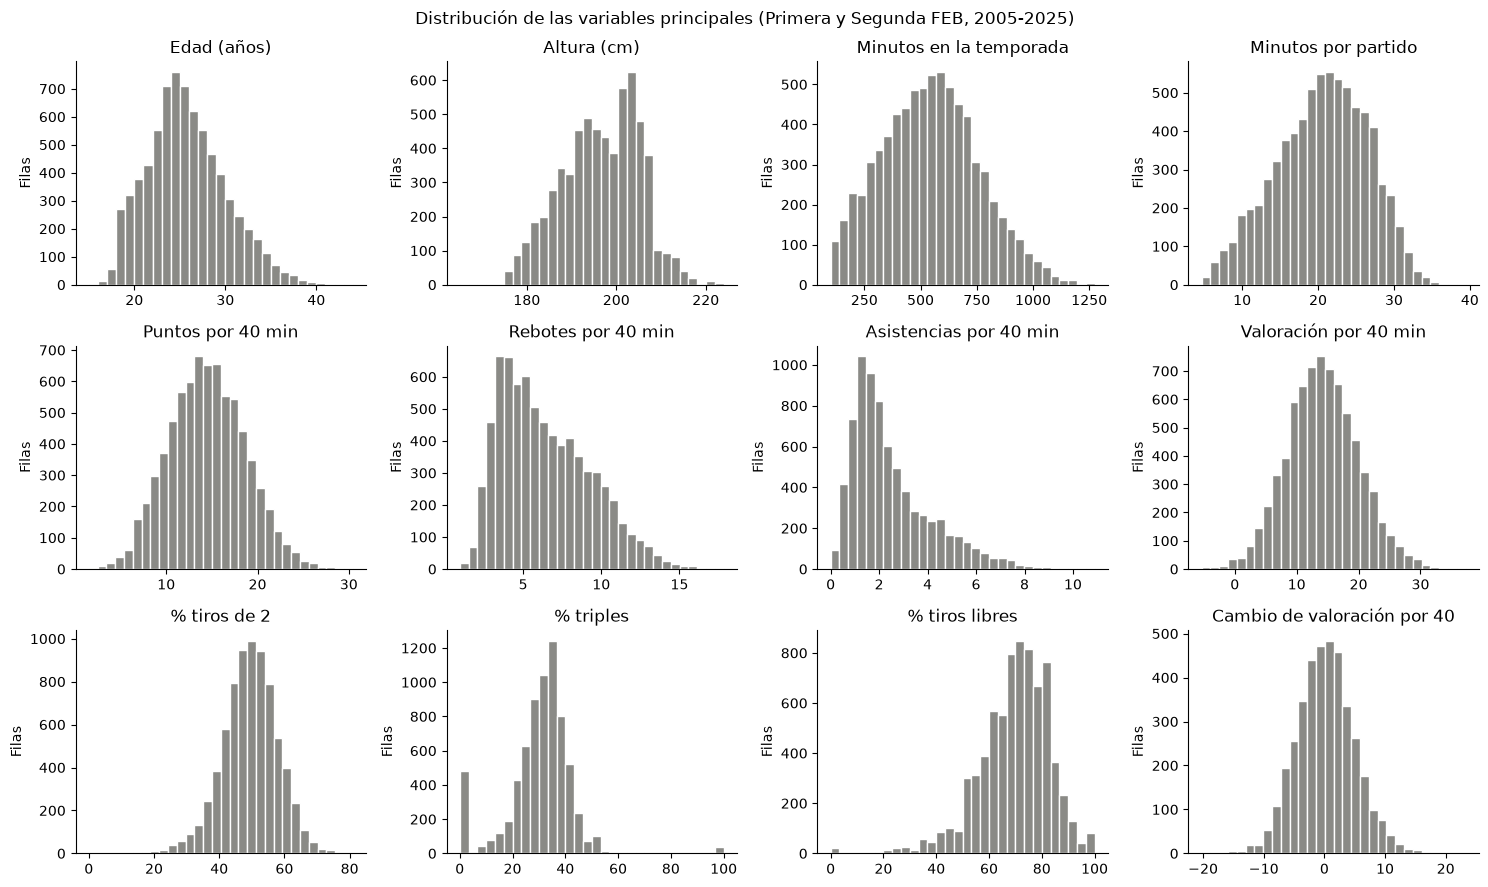

,count,mean,std,min,25%,50%,75%,max
edad,7450.0,25.2,4.3,15.0,22.0,25.0,28.0,43.0
altura_cm,6219.0,196.6,8.8,165.0,190.0,197.0,203.0,224.0
minutos,7452.0,543.5,214.2,100.3,385.4,542.2,688.2,1273.8
minutos_partido,7452.0,20.5,6.0,4.7,16.3,20.9,25.0,39.4
puntos_40,7452.0,14.5,4.2,1.5,11.5,14.4,17.3,30.4
rebotes_40,7452.0,6.4,2.9,0.9,4.1,5.9,8.4,17.8
asistencias_40,7452.0,2.5,1.7,0.0,1.3,2.0,3.3,10.9
valoracion_40,7452.0,14.2,5.8,-5.4,10.3,14.0,18.0,37.3
t2_pct,7412.0,49.4,8.6,0.0,44.2,49.7,55.0,81.0
t3_pct,6975.0,30.1,12.4,0.0,25.3,31.7,36.8,100.0


In [4]:
fig, ejes = plt.subplots(3, 4, figsize=(15, 9))
for ax, (columna, etiqueta) in zip(ejes.flat, PRINCIPALES.items()):
    bins = range(15, 45) if columna == "edad" else 30     # edad entera: un año por barra
    ax.hist(modelo[columna].dropna(), bins=bins, color="#8a8a86", edgecolor="white")
    ax.set(title=etiqueta, ylabel="Filas")
fig.suptitle("Distribución de las variables principales (Primera y Segunda FEB, 2005-2025)")
plt.tight_layout()
plt.show()
modelo[list(PRINCIPALES)].describe().T.round(1)

* Sin duplicados. Los huecos son porque no han habido datos la temporada anterior. La altura falta en algunas fichas y el % de triples tambien (seguramente sea porque no tira triples). La mayoría de los jugadores son de entre 22 y 28 años.

## 2. Cambia el nivel entre Primera y Segunda FEB?

##### Comparamos cada liga y los mimsmos jugadores cuando ascienden de categoría la temporada siguiente

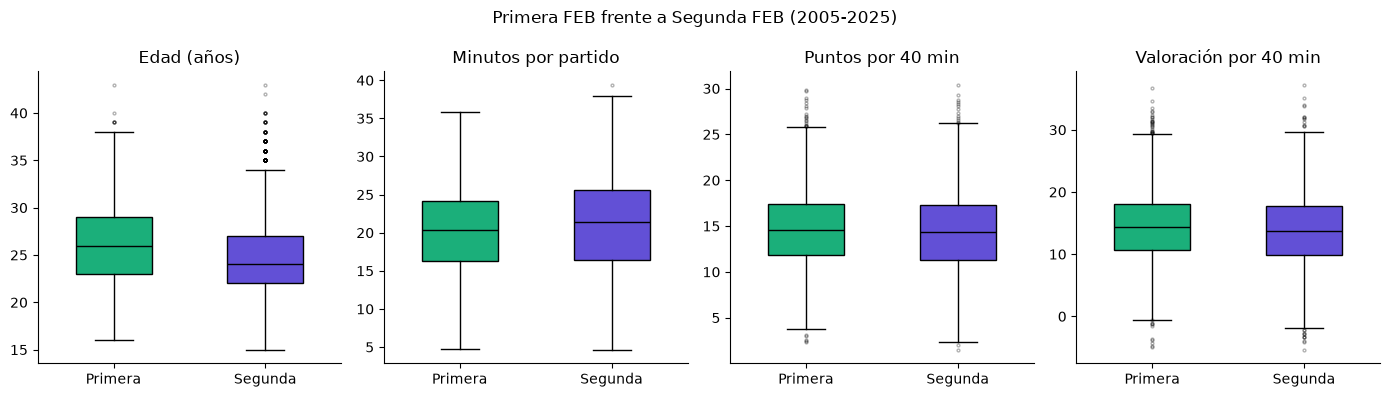

In [5]:
fig, ejes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (columna, etiqueta) in zip(ejes, [("edad", "Edad (años)"), ("minutos_partido", "Minutos por partido"),
                                          ("puntos_40", "Puntos por 40 min"), ("valoracion_40", "Valoración por 40 min")]):
    datos = [modelo.loc[modelo["competicion"] == c, columna].dropna() for c in ("primera_feb", "segunda_feb")]
    caja = ax.boxplot(datos, tick_labels=["Primera", "Segunda"], patch_artist=True, widths=0.5,
                      medianprops={"color": "black"}, flierprops={"markersize": 2, "alpha": 0.3})
    for parte, color in zip(caja["boxes"], [PRIMERA, SEGUNDA]):
        parte.set_facecolor(color)
    ax.set(title=etiqueta)
fig.suptitle("Primera FEB frente a Segunda FEB (2005-2025)")
plt.tight_layout()
plt.show()

In [6]:
columnas = ["minutos_partido", "puntos_40", "valoracion_40"]
segunda = modelo.loc[modelo["competicion"] == "segunda_feb", ["id_feb", "temporada"] + columnas]
primera = modelo.loc[modelo["competicion"] == "primera_feb", ["id_feb", "temporada"] + columnas]
suben = segunda.merge(primera.assign(temporada=primera["temporada"] - 1), on=["id_feb", "temporada"],
                      suffixes=("_segunda", "_primera"))
print(f"Jugadores que pasan de Segunda a Primera de un año al siguiente: {len(suben)}")
pd.DataFrame({"en Segunda (mediana)": [suben[f"{c}_segunda"].median() for c in columnas],
              "al año siguiente en Primera (mediana)": [suben[f"{c}_primera"].median() for c in columnas]},
             index=columnas).round(1)

Jugadores que pasan de Segunda a Primera de un año al siguiente: 468


,en Segunda (mediana),al año siguiente en Primera (mediana)
minutos_partido,24.6,18.9
puntos_40,16.3,13.5
valoracion_40,16.6,12.8


* Al ser la Primera más exigente que la Segunda, las estadísticas de los jugadores bajan un poco, por lo que las esadísticas de la Segunda no serían comparables con la Pirmera, por lo que la competición entra como variable modelo

## 3. Que minutos de la ACB lo juegan los nacionales?

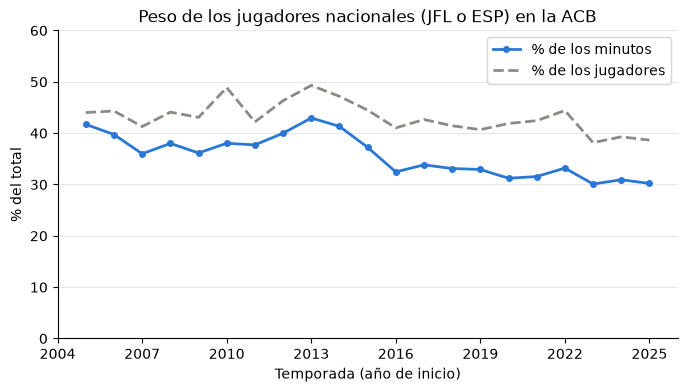

,% minutos,% jugadores
anio,,
2005,41.7,44.0
2010,38.0,48.9
2015,37.2,44.5
2020,31.2,41.9
2025,30.2,38.7


In [7]:
por_anio = acb.groupby(["anio", "nacional"])["minutos_total"].sum().unstack()
cuota = 100 * por_anio[True] / por_anio.sum(axis=1)
cuota_jugadores = 100 * acb.groupby("anio")["nacional"].mean()

fig, ax = plt.subplots()
ax.plot(cuota.index, cuota.values, color=NACIONAL, linewidth=2, marker="o", markersize=4,
        label="% de los minutos")
ax.plot(cuota_jugadores.index, cuota_jugadores.values, color="#8a8a86", linewidth=2, linestyle="--",
        label="% de los jugadores")
ax.set(title="Peso de los jugadores nacionales (JFL o ESP) en la ACB",
       xlabel="Temporada (año de inicio)", ylabel="% del total", ylim=(0, 60))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()
pd.DataFrame({"% minutos": cuota, "% jugadores": cuota_jugadores}).round(1).iloc[[0, 5, 10, 15, -1]]

* Recordemos que los jugadores nacionales son JFL o ESP. Han pasado de jugar el 42 % de los minutos en 2005 al 30 % en 2025. La diferencia entre jugadores y minutos ha crecido, es decir, siguen estando en las plantillas, pero juegan menos minutos.

## 4. Como y por donde llegan los nacionales a la ACB?

In [8]:
cobertura = cargar_datos("v_cobertura_feb")
cobertura = cobertura[cobertura["debut"].between(2006, ULTIMA_COMPLETA)]
cobertura["nacional"] = cobertura["licencia"].isin(LICENCIAS_NACIONALES)

emparejamiento = cargar_datos("emparejamiento")
primera_feb = cargar_datos("temporadas_feb").groupby("id_feb")["temporada"].min()
asentado = (acb[(acb["partidos"] >= MIN_PARTIDOS) & (acb["minutos"] >= MIN_MINUTOS)]
            .groupby("id_acb")["anio"].min().rename("primer_asentado"))

cob = (cobertura.merge(emparejamiento[["id_acb", "id_feb"]], on="id_acb", how="left")
       .join(asentado, on="id_acb"))
cob["primera_feb"] = cob["id_feb"].map(primera_feb)
cob["feb_antes_debut"] = cob["primera_feb"] <= cob["debut"]
asentados = cob[cob["primer_asentado"].notna()].copy()
asentados["feb_antes_asentarse"] = asentados["primera_feb"] < asentados["primer_asentado"]

resumen = pd.DataFrame({
    "debutantes": cob.groupby("nacional").size(),
    "con pareja en la FEB": 100 * cob.groupby("nacional")["tiene_pareja_feb"].mean(),
    "FEB antes del debut": 100 * cob.groupby("nacional")["feb_antes_debut"].mean(),
    "se asentaron": asentados.groupby("nacional").size(),
    "FEB antes de asentarse": 100 * asentados.groupby("nacional")["feb_antes_asentarse"].mean(),
}).rename(index={True: "nacional (JFL/ESP)", False: "extranjero"}).round(1)
resumen

,debutantes,con pareja en la FEB,FEB antes del debut,se asentaron,FEB antes de asentarse
nacional,,,,,
extranjero,1385,16.5,11.4,852,11.0
nacional (JFL/ESP),483,78.3,43.5,118,77.1


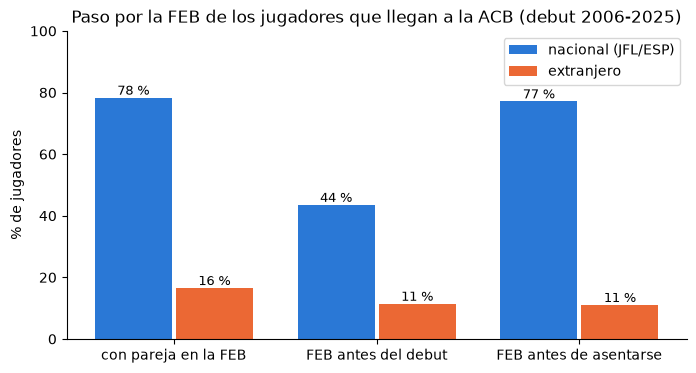

In [9]:
medidas = ["con pareja en la FEB", "FEB antes del debut", "FEB antes de asentarse"]
x = range(len(medidas))
fig, ax = plt.subplots()
ax.bar([i - 0.2 for i in x], resumen.loc["nacional (JFL/ESP)", medidas], width=0.38, color=NACIONAL,
       label="nacional (JFL/ESP)")
ax.bar([i + 0.2 for i in x], resumen.loc["extranjero", medidas], width=0.38, color=EXTRANJERO,
       label="extranjero")
for i, medida in enumerate(medidas):
    for desplazamiento, grupo in [(-0.2, "nacional (JFL/ESP)"), (0.2, "extranjero")]:
        valor = resumen.loc[grupo, medida]
        ax.text(i + desplazamiento, valor + 1, f"{valor:.0f} %", ha="center", fontsize=9)
ax.set_xticks(list(x), medidas)
ax.set(title="Paso por la FEB de los jugadores que llegan a la ACB (debut 2006-2025)",
       ylabel="% de jugadores", ylim=(0, 100))
ax.legend()
plt.show()

* el 77% de los nacionales que se asentaron en la ACB pasaron antes por las ligas inferiores de la FEB. De 483 que debutaron, solo 118 se asentaron (24% frente al 62% de los extranjeros)

## 5. Cuántos jugadores FEB se asientan y se mantienen en ACB?

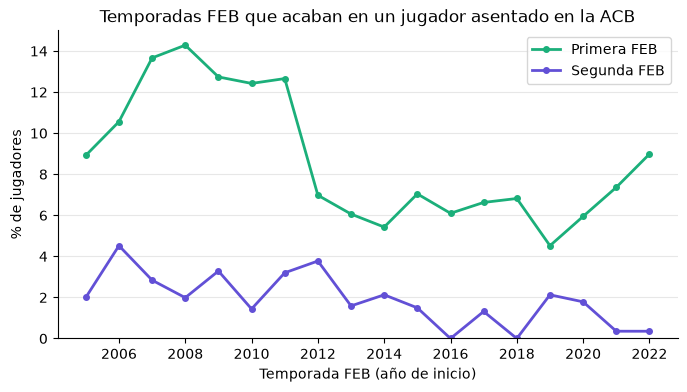

Total: 305 de 6116 (5.0%)


competicion,primera_feb,segunda_feb
periodo,,
2005-2010,12.1,2.8
2011-2016,7.5,1.9
2017-2022,6.7,0.9


In [10]:
tasa = etiquetadas.groupby(["temporada", "competicion"])["se_asienta"].mean().unstack() * 100
fig, ax = plt.subplots()
ax.plot(tasa.index, tasa["primera_feb"], color=PRIMERA, linewidth=2, marker="o", markersize=4,
        label="Primera FEB")
ax.plot(tasa.index, tasa["segunda_feb"], color=SEGUNDA, linewidth=2, marker="o", markersize=4,
        label="Segunda FEB")
ax.set(title="Temporadas FEB que acaban en un jugador asentado en la ACB",
       xlabel="Temporada FEB (año de inicio)", ylabel="% de jugadores", ylim=(0, None))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.show()

print(f"Total: {etiquetadas['se_asienta'].sum()} de {len(etiquetadas)} "
      f"({etiquetadas['se_asienta'].mean():.1%})")
etiquetadas.assign(periodo=pd.cut(etiquetadas["temporada"], [2004, 2010, 2016, 2022],
                                  labels=["2005-2010", "2011-2016", "2017-2022"])
                   ).groupby(["periodo", "competicion"], observed=True)["se_asienta"].mean().unstack().mul(100).round(1)

* 305 de 6.116 de los jugadores FEB se asienta en la ACB (5%), por lo que son muy poquitos. Desde Primera FEB se asientan muchos más que desde Segunda. Además, la proporción ha bajado con los años.

## 6. Que diferencia hay entre los que se asientan y los que no?

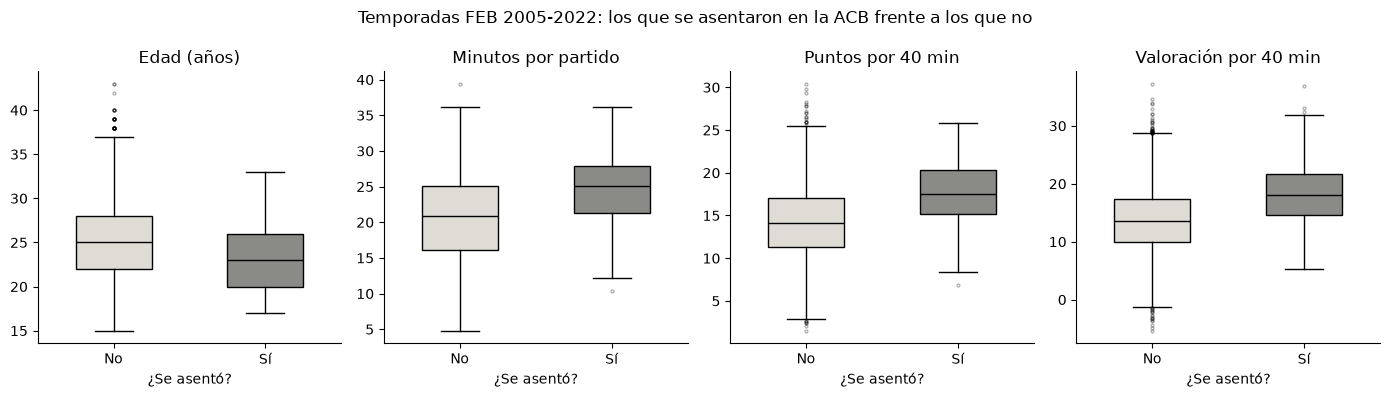

,edad,minutos_partido,puntos_40,valoracion_40
se_asienta,,,,
no,25.0,20.8,14.2,13.6
sí,23.0,25.0,17.6,18.1


In [11]:
variables = {"edad": "Edad (años)", "minutos_partido": "Minutos por partido",
             "puntos_40": "Puntos por 40 min", "valoracion_40": "Valoración por 40 min"}
fig, ejes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (columna, etiqueta) in zip(ejes, variables.items()):
    grupos = [etiquetadas.loc[etiquetadas["se_asienta"] == v, columna].dropna() for v in (0, 1)]
    caja = ax.boxplot(grupos, tick_labels=["No", "Sí"], patch_artist=True, widths=0.5,
                      medianprops={"color": "black"}, flierprops={"markersize": 2, "alpha": 0.3})
    for parte, color in zip(caja["boxes"], ["#dedcd5", "#8a8a86"]):
        parte.set_facecolor(color)
    ax.set(title=etiqueta, xlabel="¿Se asentó?")
fig.suptitle("Temporadas FEB 2005-2022: los que se asentaron en la ACB frente a los que no")
plt.tight_layout()
plt.show()

etiquetadas.groupby("se_asienta")[list(variables)].median().round(1).rename(index={0: "no", 1: "sí"})

* Los que se asientan son más jóvenes, juegan más minutos y producen más por 40 minutos. Aun así, las cajas se solapan mucho.

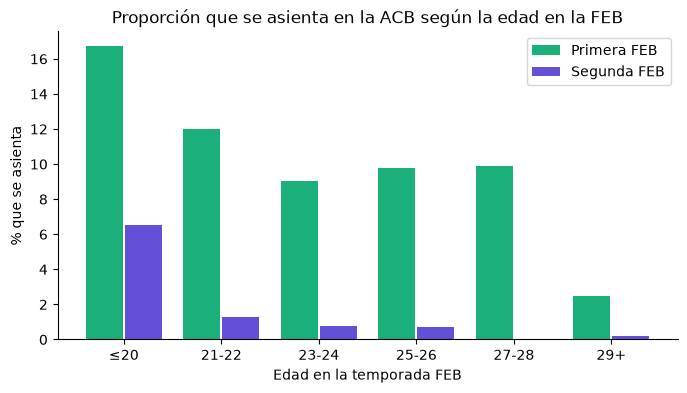

competicion,primera_feb,segunda_feb
tramo,,
≤20,16.7,6.5
21-22,12.0,1.3
23-24,9.0,0.8
25-26,9.8,0.7
27-28,9.9,0.0
29+,2.5,0.2


In [12]:
por_edad = etiquetadas.assign(tramo=pd.cut(etiquetadas["edad"], [14, 20, 22, 24, 26, 28, 45],
                                           labels=["≤20", "21-22", "23-24", "25-26", "27-28", "29+"]))
tasa_edad = por_edad.groupby(["tramo", "competicion"], observed=True)["se_asienta"].mean().unstack() * 100
fig, ax = plt.subplots()
x = range(len(tasa_edad))
ax.bar([i - 0.2 for i in x], tasa_edad["primera_feb"], width=0.38, color=PRIMERA, label="Primera FEB")
ax.bar([i + 0.2 for i in x], tasa_edad["segunda_feb"], width=0.38, color=SEGUNDA, label="Segunda FEB")
ax.set_xticks(list(x), tasa_edad.index)
ax.set(title="Proporción que se asienta en la ACB según la edad en la FEB",
       xlabel="Edad en la temporada FEB", ylabel="% que se asienta")
ax.legend()
plt.show()
tasa_edad.round(1)

* La edad importa mucho: en Primera FEB se asientan el 17 % de los que tienen 20 años o menos y solo el 2,5 % de los que tienen 29 o más. En Segunda, solo los muy jóvenes tienen opciones.

## 7. Relación entre variables entre sí y desenlace

Variables que se relacionan al objetivo y deteccion de variables casi iguales.

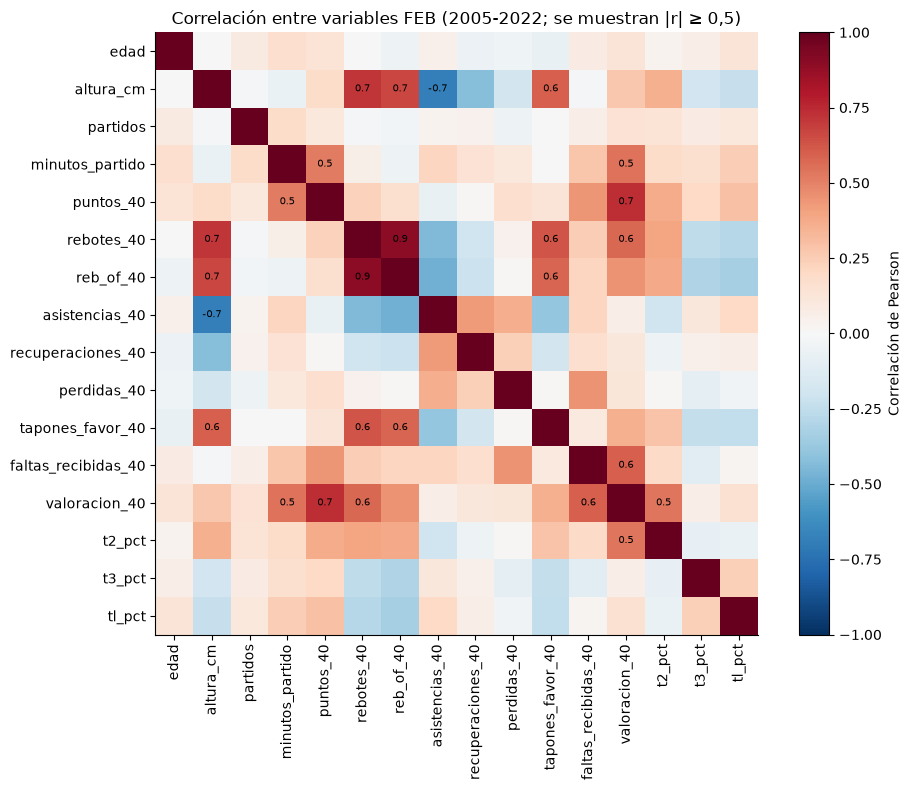

,,correlación
rebotes_40,reb_of_40,0.90
puntos_40,valoracion_40,0.74
altura_cm,rebotes_40,0.71


In [13]:
numericas = ["edad", "altura_cm", "partidos", "minutos_partido", "puntos_40", "rebotes_40",
             "reb_of_40", "asistencias_40", "recuperaciones_40", "perdidas_40", "tapones_favor_40",
             "faltas_recibidas_40", "valoracion_40", "t2_pct", "t3_pct", "tl_pct"]
correlacion = etiquetadas[numericas].corr()
fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=90)
ax.set_yticks(range(len(numericas)), numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        if i != j and abs(correlacion.iloc[i, j]) >= 0.5:
            ax.text(j, i, f"{correlacion.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Correlación entre variables FEB (2005-2022; se muestran |r| ≥ 0,5)")
plt.tight_layout()
plt.show()

pares = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1)).stack()
pares[pares.abs() >= 0.7].sort_values(key=abs, ascending=False).round(2).to_frame("correlación")

* Hay variables muy relacionadas entre sí: rebotes y rebotes ofensivos (0,9), puntos y valoración (0,74), y la altura con rebotes, tapones y asistencias(por efecto de la posición). El modelo usa regularización para que esto no le afecte.

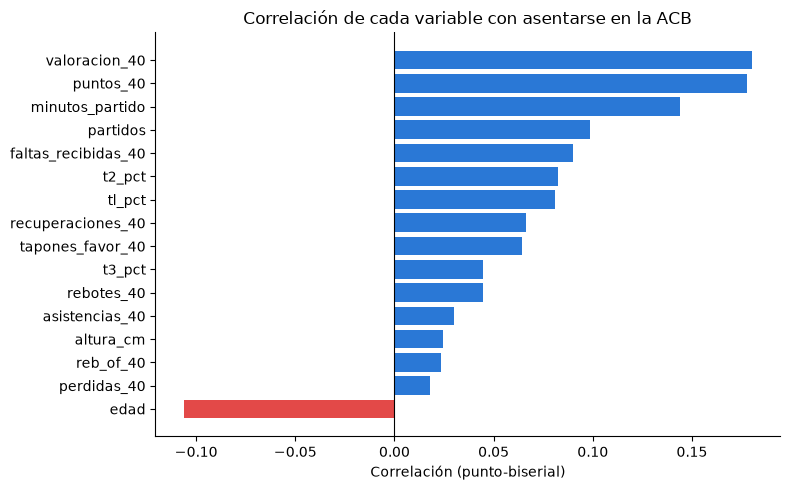

,correlación con se_asienta
valoracion_40,0.180
puntos_40,0.178
minutos_partido,0.144
partidos,0.099
faltas_recibidas_40,0.090
t2_pct,0.082
tl_pct,0.081
recuperaciones_40,0.066
tapones_favor_40,0.064
t3_pct,0.045


In [14]:
con_objetivo = etiquetadas[numericas].corrwith(etiquetadas["se_asienta"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(con_objetivo.index, con_objetivo.values,
        color=["#e34948" if v < 0 else "#2a78d6" for v in con_objetivo.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Correlación de cada variable con asentarse en la ACB", xlabel="Correlación (punto-biserial)")
plt.tight_layout()
plt.show()
con_objetivo.round(3).to_frame("correlación con se_asienta").iloc[::-1]

* Todas las correlaciones son débiles (la mayor es 0,18 en valoración y puntos por 40). La edad es la única negativa: los más jóvenes se asientan más. Ninguna variable sola sirve, por eso se combinaran en un modelo.

## 8. Importa la evolucion comparada con la temporada anterior?

Filas con temporada anterior: 3137 de 6116 (51%)


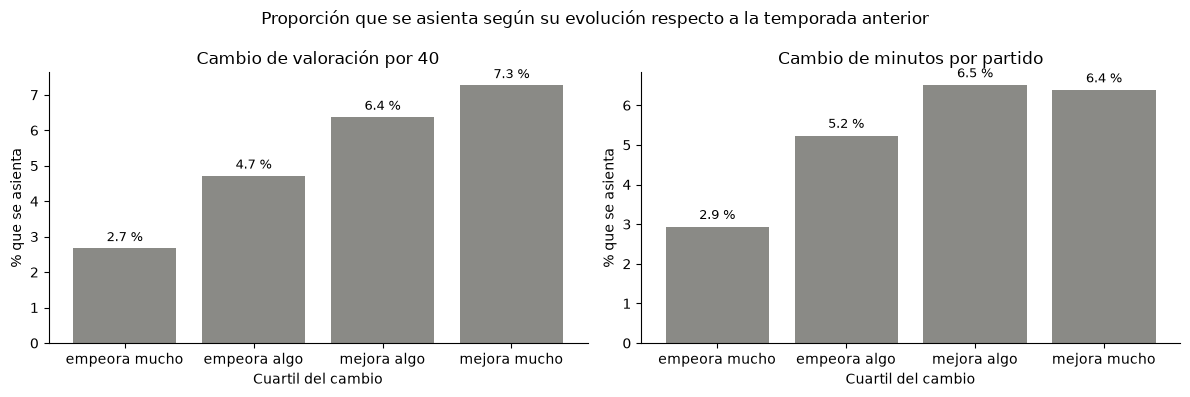

Sin temporada anterior: 4.7% · con temporada anterior: 5.3%


In [15]:
con_cambio = etiquetadas.dropna(subset=["valoracion_40_cambio", "minutos_partido_cambio"])
print(f"Filas con temporada anterior: {len(con_cambio)} de {len(etiquetadas)} "
      f"({len(con_cambio) / len(etiquetadas):.0%})")
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (columna, etiqueta) in zip(ejes, [("valoracion_40_cambio", "Cambio de valoración por 40"),
                                          ("minutos_partido_cambio", "Cambio de minutos por partido")]):
    tramos = pd.qcut(con_cambio[columna], 4, labels=["empeora mucho", "empeora algo", "mejora algo", "mejora mucho"])
    tasa = con_cambio.groupby(tramos, observed=True)["se_asienta"].mean() * 100
    ax.bar(tasa.index.astype(str), tasa.values, color="#8a8a86")
    for i, v in enumerate(tasa.values):
        ax.text(i, v + 0.2, f"{v:.1f} %", ha="center", fontsize=9)
    ax.set(title=etiqueta, xlabel="Cuartil del cambio", ylabel="% que se asienta")
fig.suptitle("Proporción que se asienta según su evolución respecto a la temporada anterior")
plt.tight_layout()
plt.show()
print("Sin temporada anterior:", f"{etiquetadas.loc[etiquetadas['valoracion_40_cambio'].isna(), 'se_asienta'].mean():.1%}",
      "· con temporada anterior:", f"{con_cambio['se_asienta'].mean():.1%}")

* Obviamente, los jugadores que mejoran respecto a la temporada anterior se asientan mucho más que los que no: los que más mejoran su valoración por 40 lo hacen un 7,3 %, frente al 2,7 % de los que más empeoran. Ganar minutos también ayuda.


## 9. Que perfil de tiro tienen los que se asientan en la ACB?

Valoramos el volumen de triples y acierto

In [16]:
tiro = etiquetadas.assign(
    triples_intentados_40=etiquetadas["t3_intentados"] * 40 / etiquetadas["minutos"],
    posicion=etiquetadas["puesto"].map(grupo_puesto).fillna("sin dato"))
con_volumen = tiro[(tiro["t3_intentados"] >= 30) & (tiro["tl_intentados"] >= 20)]
print(f"Filas con al menos 30 triples y 20 tiros libres intentados: {len(con_volumen)}")
resumen_tiro = con_volumen.groupby("se_asienta")[["triples_intentados_40", "t3_pct", "t2_pct", "tl_pct"]].median()
resumen_tiro.rename(index={0: "no se asienta", 1: "se asienta"}).round(1)

Filas con al menos 30 triples y 20 tiros libres intentados: 3534


,triples_intentados_40,t3_pct,t2_pct,tl_pct
se_asienta,,,,
no se asienta,5.5,33.3,48.6,74.4
se asienta,5.8,34.4,50.9,76.2


* Los que se asientan tiran un poco mejor, pero la diferencia es pequeña: el tiro ayuda, pero no decide.

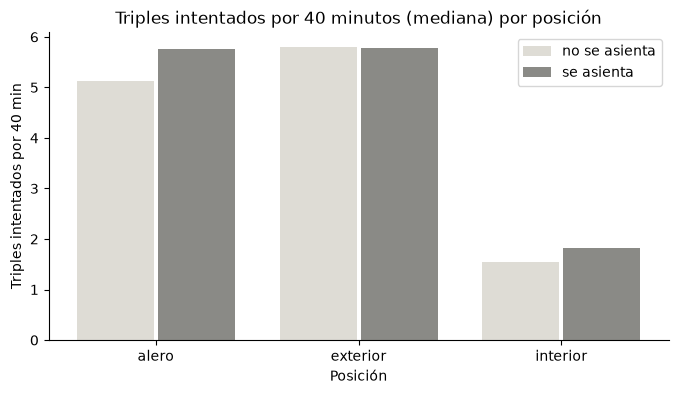

se_asienta,0,1
posicion,,
alero,5.1,5.8
exterior,5.8,5.8
interior,1.6,1.8


In [17]:
por_posicion = tiro[tiro["posicion"] != "sin dato"].groupby(["posicion", "se_asienta"])["triples_intentados_40"].median().unstack()
fig, ax = plt.subplots()
x = range(len(por_posicion))
ax.bar([i - 0.2 for i in x], por_posicion[0], width=0.38, color="#dedcd5", label="no se asienta")
ax.bar([i + 0.2 for i in x], por_posicion[1], width=0.38, color="#8a8a86", label="se asienta")
ax.set_xticks(list(x), por_posicion.index)
ax.set(title="Triples intentados por 40 minutos (mediana) por posición", xlabel="Posición",
       ylabel="Triples intentados por 40 min")
ax.legend()
plt.show()
por_posicion.round(1)

* El volumen de triples depende sobre todo de la posición (los interiores tiran muy pocos), así que hay que mirarlo junto a la posición del jugador.

## 10. Los jugadores con pasaporte español se asientan igual?

In [18]:
pasaporte = etiquetadas.assign(pasaporte=etiquetadas["es_nacional_feb"].map({1: "español", 0: "otro"}))
tabla = pasaporte.groupby(["competicion", "pasaporte"]).agg(
    filas=("se_asienta", "size"), positivos=("se_asienta", "sum"),
    tasa=("se_asienta", "mean"), edad_mediana=("edad", "median"),
    minutos_partido=("minutos_partido", "median"), valoracion_40=("valoracion_40", "median"))
tabla["tasa"] = (100 * tabla["tasa"]).round(1)
tabla.round(1)

filas  positivos  tasa  edad_mediana  minutos_partido  \
competicion pasaporte                                                          
primera_feb español     1596        126   7.9          26.0             19.5   
            otro        1243        122   9.8          25.0             22.0   
segunda_feb español     2183         28   1.3          24.0             20.8   
            otro        1094         29   2.7          24.0             23.3   

                       valoracion_40  
competicion pasaporte                 
primera_feb español             12.8  
            otro                15.9  
segunda_feb español             12.6  
            otro                15.9

* Los jugadores con pasaporte español se asientan algo menos (7,9 % frente a 9,8 % en Primera FEB), pero también juegan menos minutos y tienen menos valoración: los extranjeros de la FEB suelen ser fichajes para ser titulares.

* Hay que comprar a igualdad de rendimiento

## 11. Hay talento ESP infravalorado?

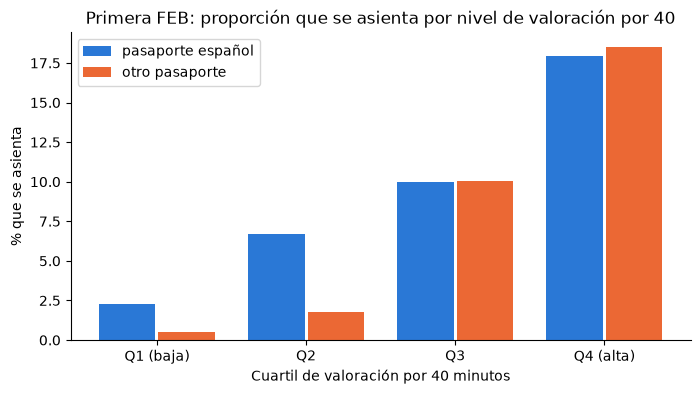

es_nacional_feb,otro pasaporte,pasaporte español
tramo,,
Q1 (baja),0.5,2.3
Q2,1.8,6.7
Q3,10.0,10.0
Q4 (alta),18.5,17.9


In [19]:
primera = etiquetadas[etiquetadas["competicion"] == "primera_feb"].copy()
primera["tramo"] = pd.qcut(primera["valoracion_40"], 4, labels=["Q1 (baja)", "Q2", "Q3", "Q4 (alta)"])
tasa = primera.groupby(["tramo", "es_nacional_feb"], observed=True)["se_asienta"].mean().unstack() * 100
fig, ax = plt.subplots()
x = range(len(tasa))
ax.bar([i - 0.2 for i in x], tasa[1], width=0.38, color=NACIONAL, label="pasaporte español")
ax.bar([i + 0.2 for i in x], tasa[0], width=0.38, color=EXTRANJERO, label="otro pasaporte")
ax.set_xticks(list(x), tasa.index)
ax.set(title="Primera FEB: proporción que se asienta por nivel de valoración por 40",
       xlabel="Cuartil de valoración por 40 minutos", ylabel="% que se asienta")
ax.legend()
plt.show()
tasa.rename(columns={1: "pasaporte español", 0: "otro pasaporte"}).round(1)

In [20]:
llegados = asentados[asentados["feb_antes_asentarse"]][["id_acb", "nacional", "primer_asentado"]]
en_acb = acb.merge(llegados.drop(columns="nacional"), on="id_acb")
en_acb = en_acb[en_acb["anio"].between(en_acb["primer_asentado"], en_acb["primer_asentado"] + 2)]
por_jugador = en_acb.groupby("id_acb").agg(minutos_total=("minutos_total", "sum"), partidos=("partidos", "sum"),
                                          valoracion_total=("valoracion_total", "sum"))
por_jugador["minutos_partido"] = por_jugador["minutos_total"] / por_jugador["partidos"]
por_jugador["valoracion_40"] = 40 * por_jugador["valoracion_total"] / por_jugador["minutos_total"]
por_jugador = por_jugador.join(llegados.set_index("id_acb")["nacional"])
por_jugador.groupby(por_jugador["nacional"].map({True: "nacional (JFL/ESP)", False: "extranjero"}))[
    ["minutos_partido", "valoracion_40"]].agg(["count", "median"]).round(1)

minutos_partido        valoracion_40       
                             count median         count median
nacional                                                      
extranjero                      94   21.0            94   15.4
nacional (JFL/ESP)              91   17.6            91   14.8

* No hay talento nacional infravalorado: con valoración alta, españoles y extranjeros se asientan igual, y con valoración baja o media los españoles se asientan más.
 
* En la ACB, los nacionales juegan menos minutos (17,6 vs. 21) con una valoración parecida. Para un club que necesita JFL, la clave es elegir bien entre muchos candidatos de nivel medio

## 12. Edad de debut en la ACB

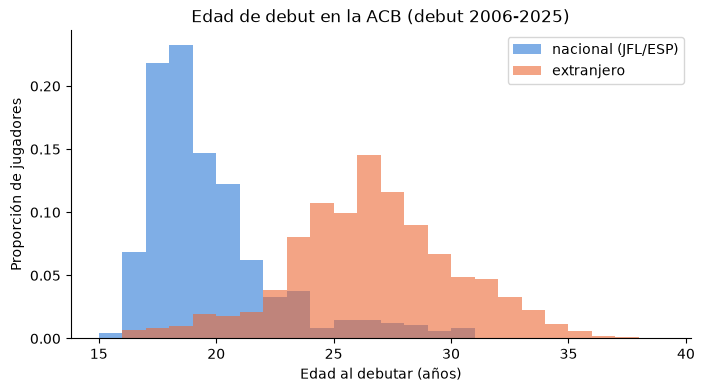

,count,mean,std,min,25%,50%,75%,max
nacional,,,,,,,,
extranjero,1385.0,26.2,3.6,16.0,24.0,26.0,28.0,37.0
nacional,483.0,19.2,2.8,14.0,17.0,18.0,20.0,30.0


In [21]:
debut = cargar_datos("v_debut_acb").merge(jugadores_acb[["id_acb", "anio_nacimiento", "nacional"]], on="id_acb")
debut = debut[debut["debut"].between(2006, ULTIMA_COMPLETA)]
debut["edad_debut"] = debut["debut"] - debut["anio_nacimiento"]
fig, ax = plt.subplots()
for valor, color, etiqueta in [(True, NACIONAL, "nacional (JFL/ESP)"), (False, EXTRANJERO, "extranjero")]:
    ax.hist(debut.loc[debut["nacional"] == valor, "edad_debut"], bins=range(15, 40), alpha=0.6,
            color=color, label=etiqueta, density=True)
ax.set(title="Edad de debut en la ACB (debut 2006-2025)", xlabel="Edad al debutar (años)",
       ylabel="Proporción de jugadores")
ax.legend()
plt.show()
debut.groupby(debut["nacional"].map({True: "nacional", False: "extranjero"}))["edad_debut"].describe().round(1)

* Los nacionales debutan en la ACB mucho antes que los extranjeros (mediana de 18 años frente a 26): los extranjeros llegan ya formados y los nacionales debutan desde la cantera. 

## 13. Influye la posicion del jugador?

In [22]:
posicion = etiquetadas.assign(posicion=etiquetadas["puesto"].map(grupo_puesto).fillna("sin dato"))
tabla_posicion = posicion.groupby("posicion").agg(filas=("se_asienta", "size"),
                                                  positivos=("se_asienta", "sum"),
                                                  tasa=("se_asienta", "mean"))
tabla_posicion["tasa"] = (100 * tabla_posicion["tasa"]).round(1)
tabla_posicion.sort_values("tasa", ascending=False)

,filas,positivos,tasa
posicion,,,
alero,673,42,6.2
sin dato,2899,163,5.6
exterior,1336,61,4.6
interior,1208,39,3.2


In [23]:
detalle = etiquetadas.assign(puesto_estandar=etiquetadas["puesto"].map(puesto_normalizado))
print("Formas distintas en la ficha:", etiquetadas["puesto"].nunique(),
      "· sin traducir:", detalle.loc[etiquetadas["puesto"].notna(), "puesto_estandar"].isna().sum())
tabla_puesto = detalle.groupby("puesto_estandar").agg(filas=("se_asienta", "size"),
                                                      positivos=("se_asienta", "sum"),
                                                      tasa=("se_asienta", "mean")).reindex(PUESTOS)
tabla_puesto["tasa"] = (100 * tabla_puesto["tasa"]).round(1)
tabla_puesto

Formas distintas en la ficha: 19 · sin traducir: 0


,filas,positivos,tasa
puesto_estandar,,,
Base,695,27,3.9
Escolta,641,34,5.3
Alero,673,42,6.2
Ala-Pívot,565,19,3.4
Pívot,643,20,3.1


* Los aleros y escoltas se asientan más que bases, ala-pívots y pívots. Un alero tiene casi el doble de opciones que un pívot. Hay que tener mucho cuidado, porque casi la mitad de los jugadores no tiene posición en la ficha y hay pocos casos por puesto.

## 14. Es comparable la Liga U con las ligas FEB?

Recordamos que La Liga U tiene solo un año

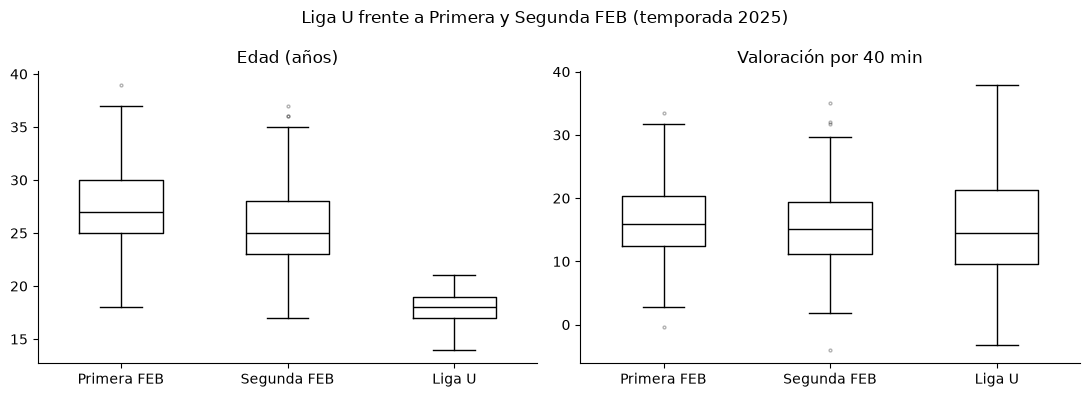

,edad,minutos_partido,puntos_40,valoracion_40
competicion,,,,
liga_u,18.0,19.8,14.8,14.5
primera_feb,27.0,19.5,15.5,15.9
segunda_feb,25.0,20.4,15.2,15.1


In [24]:
feb = cargar_datos("temporadas_feb").merge(
    cargar_datos("jugadores_feb")[["id_feb", "anio_nacimiento"]], on="id_feb")
feb["edad"] = feb["temporada"] - feb["anio_nacimiento"]
actual = feb[(feb["temporada"] == feb.loc[feb["competicion"] == "liga_u", "temporada"].max())
             & (feb["minutos"] >= 100)]
nombres = {"primera_feb": "Primera FEB", "segunda_feb": "Segunda FEB", "liga_u": "Liga U"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (columna, etiqueta) in zip(ejes, [("edad", "Edad (años)"), ("valoracion_40", "Valoración por 40 min")]):
    datos = [actual.loc[actual["competicion"] == c, columna].dropna() for c in nombres]
    ax.boxplot(datos, tick_labels=list(nombres.values()), widths=0.5, medianprops={"color": "black"},
               flierprops={"markersize": 2, "alpha": 0.3})
    ax.set(title=etiqueta)
fig.suptitle(f"Liga U frente a Primera y Segunda FEB (temporada {actual['temporada'].max()})")
plt.tight_layout()
plt.show()
actual.groupby("competicion")[["edad", "minutos_partido", "puntos_40", "valoracion_40"]].median().round(1)

* La Liga U es mucho más joven (mediana de 18 años frente a 25-27) y su producción por 40 minutos es parecida en la mediana. Como el nivel de la competición es distinto, sus números no se pueden comparar directamente con los de Primera y Segunda FEB.
* Con una sola temporada no entrará en el modelo: en la aplicación se muestra como ranking descriptivo, sin jugadores menores de edad.